## 1. Hugging Face Login

#### Imports the token from Kaggle Secrets.

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(torch.cuda.device_count())

from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF2")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

1


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [3]:
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 1
GPU 0: Tesla T4


## 3. Configuration

Student = Model 3 (GQA, Phase 1 checkpoint). Teacher = Model 4 (Prefix-LM), your full-fine-tuned Phase 2 NER checkpoint, loaded frozen. Knowledge Distillation trains the student end-to-end against a combined hard-label + soft teacher-matching loss.

In [4]:
import os, random, json, time, math, zipfile, shutil
import numpy as np
import torch

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_TEXT_FILES = ["Phase_2_LNER/Train/fold1-text.json", "Phase_2_LNER/Train/fold2-text.json"]
TRAIN_GOLD_FILES = ["Phase_2_LNER/Train/fold1-gold.json", "Phase_2_LNER/Train/fold2-gold.json"]
LABELS_FILE = "Phase_2_LNER/Train/labels.txt"
TEST_TEXT_FILE = "Phase_2_LNER/Test/fold3-text.json"

# ---------------- Student: Model 3 (GQA), Phase 1 checkpoint ----------------
PHASE1_CKPT_DIR = "/kaggle/input/datasets/himangshumahato/legal-grouped-query-lm"
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12
N_KV_HEAD = 4

# ---------------- Teacher: Model 4 (Prefix-LM), full-fine-tuned Phase 2 NER checkpoint ----------------
# Set this to wherever you uploaded that notebook's saved best_model.pt as a Kaggle Dataset.
TEACHER_CKPT_DIR = "/kaggle/input/datasets/himangshumahato/prefixlm-best-model"
TEACHER_N_EMBD, TEACHER_N_LAYER, TEACHER_N_HEAD, TEACHER_N_KV_HEAD = 768, 12, 12, 4

MODEL_CONTEXT_LENGTH = 1024
WINDOW_SIZE = 1024        # must match the teacher's own window size for aligned KD batches
WINDOW_STRIDE = 512
HEADER_TOKENS = 64

# ---------------- Knowledge Distillation ----------------
KD_TEMPERATURE = 2.0
KD_ALPHA = 0.5             # weight on hard-label loss; (1-KD_ALPHA) on soft teacher-matching loss

# ---------------- Training ----------------
EPOCHS = 20
BATCH_SIZE = 2
GRAD_ACCUM = 8
LR_BACKBONE = 3e-5
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_RATIO = 0.10
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- Kaggle output ----------------
EXPERIMENT_NAME = "gqa_kd_student"
OUTPUT_DIR = f"/kaggle/working/cs781_phase2/{EXPERIMENT_NAME}"
MODEL_PATH = os.path.join(OUTPUT_DIR, "best_model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration loaded:", EXPERIMENT_NAME)

Configuration loaded: gqa_kd_student


In [5]:
!pip -q install regex
from huggingface_hub import hf_hub_download, HfApi

In [6]:
info = HfApi().dataset_info(HF_DATASET_REPO, files_metadata=True, token=HF_TOKEN)
for s in info.siblings:
    if "Phase_2" in s.rfilename:
        print(f"{s.rfilename:70s} {s.size/1e6:.2f} MB")

Phase_2_LNER/Test/fold3-text.json                                      1.19 MB
Phase_2_LNER/Train/fold1-gold.json                                     0.46 MB
Phase_2_LNER/Train/fold1-text.json                                     1.11 MB
Phase_2_LNER/Train/fold2-gold.json                                     0.48 MB
Phase_2_LNER/Train/fold2-text.json                                     1.12 MB
Phase_2_LNER/Train/labels.txt                                          0.00 MB


## 4. Load Tokenizer

In [7]:
%%writefile a1_tokenizer.py
"""From-scratch byte-level BPE tokenizer (GPT-2 style), no external tokenizer libs.

Differences from the plain-bytes version:
  * Text is first split into "words" with a GPT-2 style regex, and merges never
    cross word boundaries. Training and encoding then work on *unique words*
    (with counts) instead of the whole corpus, which is orders of magnitude faster.
  * Training uses incremental pair counts + a lazy max-heap (no full rescan per merge).
  * Encoding applies merges per word by rank, with a word -> ids cache.
  * One special token, <|endoftext|>, used as EOS / PAD / BOS.

Interface:
    tok.encode(text, add_eos=False) -> list[int]
    tok.decode(ids, skip_special_tokens=True) -> str
    tok.vocab_size / tok.get_vocab_size()
    tok.eos_token_id, tok.pad_token_id, tok.bos_token_id
    tok.save(path) / ByteLevelBPE.load(path)
"""

from __future__ import annotations

import heapq
import json
import time
from collections import Counter, defaultdict

import regex as re  # `pip install regex` (needed for \p{L} / \p{N})

# GPT-2 pre-tokenization pattern
_PAT = re.compile(
    r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
)

EOS_TOKEN = "<|endoftext|>"


class ByteLevelBPE:
    def __init__(self):
        # ids 0-255 = raw bytes; 256.. = learned merges; last id = <|endoftext|>
        self.merges: dict[tuple[int, int], int] = {}      # (a, b) -> new_id (id order == rank order)
        self.itos: dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.eos_token_id = 256
        self.vocab_size = 257
        self._cache: dict[str, tuple] = {}

    # alias attributes so the tokenizer plugs into HF-style code
    @property
    def pad_token_id(self): return self.eos_token_id
    @property
    def bos_token_id(self): return self.eos_token_id

    def __len__(self): return self.vocab_size
    def get_vocab_size(self): return self.vocab_size

    def train(self, text: str, vocab_size: int, verbose: bool = False) -> None:
        """Learn (vocab_size - 257) merges; the final id is reserved for <|endoftext|>."""
        if vocab_size < 257:
            raise ValueError("vocab_size must be at least 257 (256 bytes + EOS)")
        num_merges = vocab_size - 257
        t0 = time.time()

        # 1) pre-tokenize and count unique words
        word_counts = Counter(_PAT.findall(text))
        words = [list(w.encode("utf-8")) for w in word_counts]
        freqs = list(word_counts.values())
        if verbose:
            print(f"[bpe] {len(words):,} unique words from {sum(freqs):,} total words")

        # 2) initial pair statistics
        stats: dict[tuple[int, int], int] = defaultdict(int)
        where: dict[tuple[int, int], set] = defaultdict(set)
        for wi, w in enumerate(words):
            f = freqs[wi]
            for p in zip(w, w[1:]):
                stats[p] += f
                where[p].add(wi)

        # lazy max-heap: (-count, a, b) -> highest count first, ties -> smallest (a, b)
        heap = [(-c, a, b) for (a, b), c in stats.items()]
        heapq.heapify(heap)

        self.merges, self.itos = {}, {i: bytes([i]) for i in range(256)}

        # 3) merge loop
        for i in range(num_merges):
            pair, count = None, 0
            while heap:
                negc, a, b = heapq.heappop(heap)
                if stats.get((a, b), 0) == -negc:   # skip stale heap entries
                    pair, count = (a, b), -negc
                    break
            if pair is None or count < 2:
                break

            new_id = 256 + i
            self.merges[pair] = new_id
            self.itos[new_id] = self.itos[pair[0]] + self.itos[pair[1]]

            touched = set()
            for wi in list(where[pair]):
                w, f = words[wi], freqs[wi]
                # remove this word's old pair contributions
                for p in zip(w, w[1:]):
                    stats[p] -= f
                    where[p].discard(wi)
                    touched.add(p)
                # apply merge (leftmost, non-overlapping)
                a, b = pair
                out, j, n = [], 0, len(w)
                while j < n:
                    if j < n - 1 and w[j] == a and w[j + 1] == b:
                        out.append(new_id); j += 2
                    else:
                        out.append(w[j]); j += 1
                words[wi] = out
                # add new pair contributions
                for p in zip(out, out[1:]):
                    stats[p] += f
                    where[p].add(wi)
                    touched.add(p)

            for p in touched:
                c = stats.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p[0], p[1]))
                else:
                    stats.pop(p, None)
                    where.pop(p, None)

            if verbose and (i % 1000 == 0 or i == num_merges - 1):
                print(f"[bpe] merge {i + 1}/{num_merges} | pair={pair} count={count:,} "
                      f"| elapsed={time.time() - t0:.1f}s")

        self.eos_token_id = 256 + len(self.merges)
        self.vocab_size = self.eos_token_id + 1
        self._cache = {}

    # Inference
    def _encode_word(self, word: str) -> tuple:
        hit = self._cache.get(word)
        if hit is not None:
            return hit
        ids = list(word.encode("utf-8"))
        merges = self.merges
        while len(ids) > 1:
            # pick the applicable merge learned earliest (lowest id)
            best, best_id = None, None
            for p in zip(ids, ids[1:]):
                nid = merges.get(p)
                if nid is not None and (best_id is None or nid < best_id):
                    best, best_id = p, nid
            if best is None:
                break
            a, b = best
            out, j, n = [], 0, len(ids)
            while j < n:
                if j < n - 1 and ids[j] == a and ids[j + 1] == b:
                    out.append(best_id); j += 2
                else:
                    out.append(ids[j]); j += 1
            ids = out
        res = tuple(ids)
        if len(self._cache) > 2_000_000:
            self._cache.clear()
        self._cache[word] = res
        return res

    def encode(self, text: str, add_eos: bool = False) -> list[int]:
        ids: list[int] = []
        for w in _PAT.findall(text):
            ids.extend(self._encode_word(w))
        if add_eos:
            ids.append(self.eos_token_id)
        return ids

    def decode(self, ids, skip_special_tokens: bool = True) -> str:
        if hasattr(ids, "tolist"):
            ids = ids.tolist()
        parts = []
        for i in ids:
            if i == self.eos_token_id:
                if not skip_special_tokens:
                    parts.append(EOS_TOKEN.encode("utf-8"))
                continue
            parts.append(self.itos[i])
        return b"".join(parts).decode("utf-8", errors="replace")

    def save(self, path: str) -> None:
        data = {
            "merges": [[a, b, nid] for (a, b), nid in self.merges.items()],
            "vocab_size": self.vocab_size,
            "eos_token_id": self.eos_token_id,
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f)

    @classmethod
    def load(cls, path: str) -> "ByteLevelBPE":
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls()
        for a, b, nid in data["merges"]:
            tok.merges[(a, b)] = nid
            tok.itos[nid] = tok.itos[a] + tok.itos[b]
        tok.eos_token_id = data["eos_token_id"]
        tok.vocab_size = data["vocab_size"]
        return tok


def train_tokenizer(train_text: str, vocab_size: int):
    """Train a byte-level BPE tokenizer on `train_text` and return it."""
    tok = ByteLevelBPE()
    tok.train(train_text, vocab_size, verbose=True)
    return tok

Writing a1_tokenizer.py


In [8]:
from a1_tokenizer import ByteLevelBPE, _PAT

tokenizer = ByteLevelBPE.load(os.path.join(PHASE1_CKPT_DIR, "bpe_tokenizer.json"))
print("Vocabulary size:", len(tokenizer))

Vocabulary size: 32000


In [9]:
def encode_with_offsets(tok, text):
    """Returns ids, starts, ends, is_ws. Offsets are character offsets into `text`,
    end-exclusive, with leading/trailing whitespace trimmed from each token's span.
    is_ws[i] is True for tokens that are whitespace only (no usable span)."""
    ids, starts, ends, is_ws = [], [], [], []
    pos = 0
    for m in _PAT.finditer(text):
        assert m.start() == pos, "pre-tokenizer left a gap in the text"
        pos = m.end()
        word, c0 = m.group(), m.start()
        b2c = []
        for i, ch in enumerate(word):
            b2c.extend([c0 + i] * len(ch.encode("utf-8")))
        b = 0
        for tid in tok._encode_word(word):
            n = len(tok.itos[tid])
            s, e = b2c[b], b2c[b + n - 1] + 1
            b += n
            while s < e and text[s].isspace(): s += 1
            while e > s and text[e - 1].isspace(): e -= 1
            ids.append(tid); starts.append(s); ends.append(e); is_ws.append(s >= e)
    assert pos == len(text), "pre-tokenizer did not cover the whole text"
    return ids, starts, ends, is_ws

## Data loading

In [10]:
from huggingface_hub import hf_hub_download

def hf_json(path):
    p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=path,
                        repo_type="dataset", token=HF_TOKEN)
    with open(p, encoding="utf-8") as f:
        return json.load(f)

train_text, train_gold, doc_fold = {}, {}, {}
for fold_i, (tf, gf) in enumerate(zip(TRAIN_TEXT_FILES, TRAIN_GOLD_FILES), start=1):
    t, g = hf_json(tf), hf_json(gf)
    train_text.update(t); train_gold.update(g)
    for d in t: doc_fold[d] = fold_i

test_text = hf_json(TEST_TEXT_FILE)

p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=LABELS_FILE,
                    repo_type="dataset", token=HF_TOKEN)
LABELS = [l.strip() for l in open(p, encoding="utf-8") if l.strip()]

print("train docs:", len(train_text), "| gold docs:", len(train_gold), "| test docs:", len(test_text))
print({f: sum(1 for v in doc_fold.values() if v == f) for f in (1, 2)})

fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

train docs: 70 | gold docs: 70 | test docs: 35
{1: 35, 2: 35}


In [11]:
for d in list(train_text)[:5]:
    ids, s, e, w = encode_with_offsets(tokenizer, train_text[d])
    assert ids == tokenizer.encode(train_text[d]), d
print("ids match encode()")

n_tok = [len(encode_with_offsets(tokenizer, t)[0]) for t in train_text.values()]
print("tokens/doc min/mean/max:", min(n_tok), sum(n_tok)//len(n_tok), max(n_tok))

ids match encode()
tokens/doc min/mean/max: 2139 6618 23839


In [12]:
TAGS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(TAGS)}
ID2TAG = {i: t for t, i in TAG2ID.items()}
IGNORE = -100
print(len(TAGS), "tags:", TAGS[:5], "...")

25 tags: ['O', 'B-APP', 'I-APP', 'B-RESP', 'I-RESP'] ...


In [13]:
def spans_to_bio(starts, ends, is_ws, gold_spans):
    """One tag id per token. gold_spans: [[start, end, label, (text)], ...]"""
    ents = sorted(gold_spans, key=lambda x: (x[0], x[1]))
    tags = []
    k = 0
    prev_ent = -1
    for i in range(len(starts)):
        if is_ws[i]:
            tags.append(IGNORE)
            continue
        while k < len(ents) and ents[k][1] <= starts[i]:
            k += 1
        if k < len(ents) and ents[k][0] <= starts[i] < ents[k][1]:
            prefix = "I-" if prev_ent == k else "B-"
            tags.append(TAG2ID[prefix + ents[k][2]])
            prev_ent = k
        else:
            tags.append(TAG2ID["O"])
            prev_ent = -1
    return tags


def bio_to_spans(starts, ends, is_ws, tag_ids):
    """List of [start_char, end_char, label] from per-token tag ids."""
    spans, cur = [], None
    for i, t in enumerate(tag_ids):
        if is_ws[i] or t == IGNORE:
            continue
        tag = ID2TAG[int(t)]
        if tag == "O":
            if cur: spans.append(cur); cur = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "I" and cur is not None and cur[2] == label:
            cur[1] = ends[i]
        else:
            if cur: spans.append(cur)
            cur = [starts[i], ends[i], label]
    if cur: spans.append(cur)
    return spans


def span_set(spans):
    return {tuple(x[:3]) for x in spans}

In [14]:
tp = ngold = 0
fails = []
for d, ents in train_gold.items():
    text = train_text[d]
    ids, s, e, w = encode_with_offsets(tokenizer, text)
    tags = spans_to_bio(s, e, w, ents)
    back = bio_to_spans(s, e, w, tags)
    g, b = span_set(ents), span_set(back)
    tp += len(g & b); ngold += len(g)
    for x in ents:
        if tuple(x[:3]) not in b:
            fails.append((d, x[0], x[1], x[2], text[max(0, x[0]-10):x[1]+10]))

print(f"round-trip recovery: {tp}/{ngold} = {tp/ngold:.4f}")
for f in fails[:15]:
    print(f)

round-trip recovery: 8242/8393 = 0.9820
('115651329', 10266, 10299, 'PREC', 'e case of State of M.P. vs. Kashiram & Ors.[1], the s')
('975074', 7995, 8085, 'PREC', '1565] and Gambangi Appalaswamy Naldu and Others v. Behara Venkataramanayya Patro [AIR 1984- SC 1728]. Even oth')
('736324', 1963, 1976, 'AUTH', ' down the Railway Boards instruct')
('736324', 11218, 11231, 'AUTH', 'tation of Railway Boards decision')
('736324', 12849, 12901, 'PREC', ' cases in Shankarsan Dash Vs. Union of India [1991 (3) SCC 47]. Para 7 o')
('736324', 14121, 14174, 'PREC', 'C 268] or Jatendra Kumar vs. State of Punjab [(1985) 1 SCC 122]. Hence th')
('1243363', 17853, 17865, 'STAT', 'After the Constitutional Amendme')
('1243363', 25083, 25099, 'AUTH', 'uding the State Governments and the ')
('1243363', 25450, 25466, 'AUTH', 'ws of the State Governments and the ')
('373587', 5927, 5979, 'PREC', 'son. (See Hukam Singh v. State of Rajasthan AIR (1977 SC 1063); Eradu an')
('373587', 5981, 6035, 'PREC', 'SC 1063)

## Encode every document once (train and test)

In [15]:
enc = {}
for d, t in {**train_text, **test_text}.items():
    enc[d] = encode_with_offsets(tokenizer, t)

tags_by_doc = {d: spans_to_bio(*enc[d][1:], train_gold[d]) for d in train_gold}
print("encoded docs:", len(enc), "| tagged docs:", len(tags_by_doc))

encoded docs: 105 | tagged docs: 70


## Windows

Header-injected sliding windows: every non-first window carries the document's first `HEADER_TOKENS` as extra bidirectional context, so repeat-litigant / role-disambiguation cues near the document start aren't lost to windowing. Train/val split is a random 10% of documents across both folds (matches the teacher's own split, required for aligned KD batches).

In [16]:
def window_starts(n_tokens, size, stride):
    if n_tokens <= size:
        return [0]
    starts = list(range(0, n_tokens - size + 1, stride))
    if starts[-1] + size < n_tokens:
        starts.append(n_tokens - size)
    return starts


def build_windows(doc_ids, size=WINDOW_SIZE, stride=WINDOW_STRIDE, with_labels=True, header_tokens=HEADER_TOKENS):
    items = []
    body_size = size - header_tokens
    for d in doc_ids:
        ids = enc[d][0]
        tags = tags_by_doc.get(d) if with_labels else None
        n = len(ids)
        header_ids = ids[:header_tokens]
        for ws in window_starts(n, body_size, stride):
            if ws == 0:
                input_ids = ids[0:size]
                body_start = 0
            else:
                input_ids = header_ids + ids[ws:ws + body_size]
                body_start = header_tokens
            body_len = len(input_ids) - body_start
            item = {"doc": d, "doc_start": ws, "body_start": body_start, "input_ids": input_ids}
            if with_labels:
                item["labels"] = [IGNORE] * body_start + tags[ws:ws + body_len]
            items.append(item)
    return items


fold1_docs = [d for d, f in doc_fold.items() if f == 1]
fold2_docs = [d for d, f in doc_fold.items() if f == 2]
all_docs = fold1_docs + fold2_docs
random.Random(SEED).shuffle(all_docs)
n_val = max(1, int(0.1 * len(all_docs)))
val_docs, train_docs = all_docs[:n_val], all_docs[n_val:]

train_items = build_windows(train_docs)
val_items   = build_windows(val_docs)
print(f"train docs: {len(train_docs)} | val docs: {len(val_docs)} | train windows: {len(train_items)} | val windows: {len(val_items)}")

for d in train_docs[:5]:
    covered = set()
    for it in train_items:
        if it["doc"] == d:
            body_len = len(it["input_ids"]) - it["body_start"]
            covered.update(range(it["doc_start"], it["doc_start"] + body_len))
    assert covered == set(range(len(enc[d][0]))), d
print("window coverage OK")

train docs: 63 | val docs: 7 | train windows: 807 | val windows: 73
window coverage OK


## Collator

In [17]:
PAD_ID = tokenizer.eos_token_id

def ner_collator(batch):
    L = WINDOW_SIZE
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    lab = torch.full((len(batch), L), IGNORE, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.bool)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        mask[i, :n] = True
        if "labels" in b:
            lab[i, :n] = torch.tensor(b["labels"])
    return {"input_ids": ids, "attention_mask": mask, "labels": lab}

b = ner_collator(train_items[:4])
print({k: v.shape for k, v in b.items()})

{'input_ids': torch.Size([4, 1024]), 'attention_mask': torch.Size([4, 1024]), 'labels': torch.Size([4, 1024])}


In [18]:
ent_frac = np.mean([any(l not in (0, IGNORE) for l in it["labels"]) for it in train_items])
print(f"windows containing at least one entity: {ent_frac:.2%}")

windows containing at least one entity: 99.38%


## 9. Define The Models

### Student backbone: Model 3 (GQA)

In standard Multi-Head Attention (MHA), every query head has its own dedicated key and value head. In GQA, query heads are divided into groups, and all queries within a group share the same key/value head, drastically reducing KV-cache size during inference while staying much closer to MHA than Multi-Query Attention (MQA).

This version adds explicit `attn_mask` support (absent in the Phase 1 pretraining code), so the NER head can use full bidirectional attention rather than the causal-only mask used for language modeling.

In [19]:
import math
import torch.nn as nn
import torch.nn.functional as F

class GroupedQueryAttention(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        assert n_embd % n_head == 0
        assert n_head % n_kv_head == 0

        self.n_head = n_head
        self.n_kv_head = n_kv_head
        self.head_dim = n_embd // n_head
        self.num_groups = n_head // n_kv_head

        self.q_proj = nn.Linear(n_embd, n_embd)
        self.k_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.v_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.c_proj = nn.Linear(n_embd, n_embd)

        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        self.register_buffer(
            "bias",
            torch.tril(torch.ones(n_positions, n_positions)).view(1, 1, n_positions, n_positions)
        )

    def forward(self, x, layer_past=None, attn_mask=None):
        B, T, C = x.size()

        q = self.q_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)

        if layer_past is not None:
            past_k, past_v = layer_past
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)

        present = (k, v)
        past_length = layer_past[0].size(-2) if layer_past is not None else 0
        seq_len = T + past_length

        k = k.repeat_interleave(self.num_groups, dim=1)
        v = v.repeat_interleave(self.num_groups, dim=1)

        att = q @ k.transpose(-2, -1)
        att = att * (1.0 / math.sqrt(self.head_dim))

        if attn_mask is not None:
            # attn_mask: True = allowed, shape (B, 1, T, seq_len) -- used for bidirectional NER attention
            att = att.masked_fill(~attn_mask, float('-inf'))
        else:
            mask = self.bias[:, :, past_length:past_length + T, :seq_len] == 0
            att = att.masked_fill(mask, float('-inf'))

        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)

        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        return self.resid_dropout(self.c_proj(y)), present


class GQATransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = GroupedQueryAttention(n_embd, n_head, n_kv_head, n_positions, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        self.mlp = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(approximate='tanh'),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x, layer_past=None, attn_mask=None):
        attn_out, present = self.attn(self.ln_1(x), layer_past=layer_past, attn_mask=attn_mask)
        x = x + attn_out
        x = x + self.mlp(self.ln_2(x))
        return x, present


class ScratchGroupedQueryLM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, n_kv_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)

        self.h = nn.ModuleList([
            GQATransformerBlock(n_embd, n_head, n_kv_head, n_positions, dropout)
            for _ in range(n_layer)
        ])

        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

### Teacher backbone: Model 4 (Prefix-LM), loaded frozen

Reuses the same `GQATransformerBlock` defined above -- only `PrefixLM`'s embedding/head and its already-fine-tuned weights differ.

In [20]:
class PrefixLM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, n_kv_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)
        self.h = nn.ModuleList([
            GQATransformerBlock(n_embd, n_head, n_kv_head, n_positions, dropout)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

## The NER model

Shared wrapper for both student and teacher: bidirectional attention, an MLP classification head, and a `return_logits_only` flag used during distillation (so the teacher's forward pass doesn't need labels).

In [21]:
class NERModel(nn.Module):
    def __init__(self, lm, n_tags, n_embd, dropout=0.1):
        super().__init__()
        self.lm = lm
        if hasattr(self.lm, "lm_head"):
            del self.lm.lm_head        # NER doesn't predict next tokens
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(n_embd, n_embd),
            nn.GELU(approximate='tanh'),
            nn.Dropout(dropout),
            nn.Linear(n_embd, n_tags)
        )

    def forward(self, input_ids, labels=None, attention_mask=None, class_weights=None, return_logits_only=False):
        B, T = input_ids.shape
        positions = torch.arange(T, device=input_ids.device)
        x = self.lm.wte(input_ids) + self.lm.wpe(positions)
        x = self.lm.drop(x)

        attn_mask = torch.ones(B, 1, T, T, dtype=torch.bool, device=input_ids.device)
        if attention_mask is not None:
            key_visible = attention_mask[:, None, None, :].bool()
            attn_mask = attn_mask & key_visible

        for block in self.lm.h:
            x, _ = block(x, attn_mask=attn_mask)

        x = self.lm.ln_f(x)
        logits = self.head(self.dropout(x))

        if return_logits_only:
            return logits

        loss = None
        if labels is not None:
            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)), labels.view(-1),
                weight=class_weights, ignore_index=IGNORE
            )
        return {"loss": loss, "logits": logits}

## Knowledge Distillation loss

Combines standard hard-label cross-entropy with a KL-divergence term matching the student's softened predictions to the teacher's, at temperature `T`.

In [22]:
def distillation_loss(student_logits, teacher_logits, labels, class_weights, T=KD_TEMPERATURE, alpha=KD_ALPHA):
    hard = F.cross_entropy(
        student_logits.view(-1, student_logits.size(-1)), labels.view(-1),
        weight=class_weights, ignore_index=IGNORE
    )
    mask = (labels.view(-1) != IGNORE)
    s_flat = student_logits.view(-1, student_logits.size(-1))[mask]
    t_flat = teacher_logits.view(-1, teacher_logits.size(-1))[mask]
    soft = F.kl_div(
        F.log_softmax(s_flat / T, dim=-1), F.softmax(t_flat / T, dim=-1), reduction="batchmean"
    ) * (T ** 2)
    return alpha * hard + (1 - alpha) * soft

## Load the teacher (frozen) and the student (fully trainable)

In [23]:
from torch.utils.data import DataLoader
from torch.optim import AdamW
from safetensors.torch import load_file

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Teacher: Prefix-LM, loaded with its fine-tuned NER weights, fully frozen
teacher_lm = PrefixLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
                       n_embd=TEACHER_N_EMBD, n_layer=TEACHER_N_LAYER, n_head=TEACHER_N_HEAD,
                       n_kv_head=TEACHER_N_KV_HEAD)
teacher_model = NERModel(teacher_lm, n_tags=len(TAGS), n_embd=TEACHER_N_EMBD).to(device)
teacher_model.load_state_dict(torch.load(os.path.join(TEACHER_CKPT_DIR, "best_model.pt"), weights_only=True))
teacher_model.eval()
for p in teacher_model.parameters():
    p.requires_grad = False
print("Teacher loaded, frozen.")

# 2. Student: Model 3 (GQA) backbone from Phase 1, fully trainable
student_lm = ScratchGroupedQueryLM(
    vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
    n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD, n_kv_head=N_KV_HEAD,
)
state = load_file(os.path.join(PHASE1_CKPT_DIR, "model.safetensors"))
print(student_lm.load_state_dict(state))      # should say <All keys matched successfully>

ner_model = NERModel(student_lm, n_tags=len(TAGS), n_embd=N_EMBD).to(device)
for p in ner_model.parameters():
    p.requires_grad = True

# 3. Class weights, inverse-frequency, clipped
tag_counts = {i: 0 for i in range(len(TAGS))}
total_valid_tokens = 0
for item in train_items:
    for label in item["labels"]:
        if label != IGNORE:
            tag_counts[label] += 1
            total_valid_tokens += 1

class_weights_list = []
for i in range(len(TAGS)):
    count = tag_counts[i]
    class_weights_list.append(total_valid_tokens / (len(TAGS) * count) if count > 0 else 0.0)
class_weights = torch.tensor(np.clip(class_weights_list, 0.1, 10.0), dtype=torch.float).to(device)
print("Class weights calculated.")

# 4. Differential LR: backbone (full fine-tuning, low LR) vs. head (new, higher LR)
backbone_params = [p for n, p in ner_model.named_parameters() if "head" not in n]
head_params = [p for n, p in ner_model.named_parameters() if "head" in n]
optimizer = AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": head_params, "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

trainable = sum(p.numel() for p in ner_model.parameters() if p.requires_grad)
teacher_params = sum(p.numel() for p in teacher_model.parameters())
print(f"Student trainable parameters: {trainable:,}")
print(f"Teacher parameters: {teacher_params:,}")

# 5. DataLoaders and schedule
train_loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=ner_collator)
val_loader   = DataLoader(val_items,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=ner_collator)

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)

def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
print("Optimizer steps:", total_steps, "| warmup:", warmup_steps)

@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        out = model(**b)
        k = (b["labels"] != IGNORE).sum().item()
        tot += out["loss"].item() * k; n += k
    return tot / n

Teacher loaded, frozen.
<All keys matched successfully>
Class weights calculated.
Student trainable parameters: 101,578,777
Teacher parameters: 101,578,777
Optimizer steps: 1020 | warmup: 102


## Predict a document and merge overlapping windows

Header-aware log-probability averaging, followed by Viterbi decoding constrained to valid BIO transitions.

In [24]:
@torch.no_grad()
def predict_doc_logprobs(model, doc_id, size=WINDOW_SIZE, stride=WINDOW_STRIDE, bs=16, header_tokens=HEADER_TOKENS):
    model.eval()
    ids = enc[doc_id][0]
    n = len(ids)
    header_ids = ids[:header_tokens]
    body_size = size - header_tokens
    acc = torch.zeros(n, len(TAGS))
    cnt = torch.zeros(n)

    windows = []
    for ws in window_starts(n, body_size, stride):
        if ws == 0:
            windows.append({"input_ids": ids[0:size], "doc_start": ws, "body_start": 0})
        else:
            windows.append({"input_ids": header_ids + ids[ws:ws + body_size], "doc_start": ws, "body_start": header_tokens})

    for i in range(0, len(windows), bs):
        chunk = windows[i:i + bs]
        batch = ner_collator([{"input_ids": w["input_ids"]} for w in chunk])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(device))["logits"]
        lp = logits.float().log_softmax(-1).cpu()
        for j, w in enumerate(chunk):
            body_len = len(w["input_ids"]) - w["body_start"]
            doc_slice = lp[j, w["body_start"]:w["body_start"] + body_len]
            acc[w["doc_start"]:w["doc_start"] + body_len] += doc_slice
            cnt[w["doc_start"]:w["doc_start"] + body_len] += 1
    return acc / cnt[:, None]


K = len(TAGS)
trans_ok = np.zeros((K, K), dtype=bool)
for i, from_tag in enumerate(TAGS):
    for j, to_tag in enumerate(TAGS):
        if to_tag == "O":
            trans_ok[i, j] = True
        else:
            to_prefix, to_label = to_tag.split("-", 1)
            if to_prefix == "B":
                trans_ok[i, j] = True
            else:
                if from_tag == "O":
                    trans_ok[i, j] = False
                else:
                    from_prefix, from_label = from_tag.split("-", 1)
                    trans_ok[i, j] = (from_label == to_label)

NEG_INF = -1e9

def viterbi_decode(logprobs):
    T, K_ = logprobs.shape
    dp = np.full((T, K_), NEG_INF)
    bp = np.zeros((T, K_), dtype=np.int32)
    dp[0] = logprobs[0]
    for t in range(1, T):
        scores = np.where(trans_ok, dp[t - 1][:, None], NEG_INF)
        bp[t] = np.argmax(scores, axis=0)
        dp[t] = scores[bp[t], np.arange(K_)] + logprobs[t]
    path = np.empty(T, dtype=np.int32)
    path[-1] = int(np.argmax(dp[-1]))
    for t in range(T - 1, 0, -1):
        path[t - 1] = bp[t, path[t]]
    return path


def predict_spans(model, doc_id):
    ids = enc[doc_id][0]
    if len(ids) == 0:
        return []
    avg = predict_doc_logprobs(model, doc_id)
    tag_ids = viterbi_decode(avg.numpy())
    _, s, e, w = enc[doc_id]
    return bio_to_spans(s, e, w, tag_ids.tolist())

## Strict scorer

In [25]:
def strict_scores(gold_by_doc, pred_by_doc, verbose=True):
    cnts = {l: [0, 0, 0] for l in LABELS}
    for d, gold in gold_by_doc.items():
        g = {tuple(x[:3]) for x in gold}
        p = {tuple(x[:3]) for x in pred_by_doc.get(d, [])}
        for l in LABELS:
            gl = {x for x in g if x[2] == l}
            pl = {x for x in p if x[2] == l}
            cnts[l][0] += len(gl & pl); cnts[l][1] += len(pl); cnts[l][2] += len(gl)
    rows, Ps, Rs, Fs = [], [], [], []
    for l in LABELS:
        tp, npred, ngold = cnts[l]
        P = tp / npred if npred else 0.0
        R = tp / ngold if ngold else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        Ps.append(P); Rs.append(R); Fs.append(F)
        rows.append((l, P, R, F, ngold))
    if verbose:
        print(f"{'label':10s} {'P':>6s} {'R':>6s} {'F1':>6s} {'#gold':>6s}")
        for l, P, R, F, n in rows:
            print(f"{l:10s} {P:6.3f} {R:6.3f} {F:6.3f} {n:6d}")
    macro = (sum(Ps) / len(Ps), sum(Rs) / len(Rs), sum(Fs) / len(Fs))
    print(f"MACRO  P {macro[0]:.4f}  R {macro[1]:.4f}  F1 {macro[2]:.4f}")
    return macro

## 11. Training

In [26]:
PATIENCE = 5
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
history = {"train": [], "val": [], "f1": []}
best_f1, bad_epochs = 0.0, 0

val_gold = {d: train_gold[d] for d in val_docs}
t0 = time.time()
for epoch in range(EPOCHS):
    ner_model.train()
    run, cnt = 0.0, 0
    optimizer.zero_grad()
    for i, b in enumerate(train_loader):
        b = {k: v.to(device) for k, v in b.items()}

        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            teacher_logits = teacher_model(input_ids=b["input_ids"], attention_mask=b["attention_mask"],
                                           return_logits_only=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            student_logits = ner_model(input_ids=b["input_ids"], attention_mask=b["attention_mask"],
                                       return_logits_only=True)
            loss = distillation_loss(student_logits, teacher_logits, b["labels"], class_weights)

        scaler.scale(loss / GRAD_ACCUM).backward()
        run += loss.item(); cnt += 1
        if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(ner_model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(); scheduler.step()

    v = eval_loss(ner_model, val_loader)
    val_pred = {d: predict_spans(ner_model, d) for d in val_docs}
    f1 = strict_scores(val_gold, val_pred, verbose=False)[2]
    history["train"].append(run / cnt); history["val"].append(v); history["f1"].append(f1)
    print(f"epoch {epoch+1}/{EPOCHS} | train {run/cnt:.4f} | val loss {v:.4f} | val F1 {f1:.4f} | {time.time()-t0:.0f}s")

    if f1 > best_f1:
        best_f1, bad_epochs = f1, 0
        torch.save(ner_model.state_dict(), MODEL_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"early stopping at epoch {epoch+1} (best F1 {best_f1:.4f})")
            break

ner_model.load_state_dict(torch.load(MODEL_PATH, weights_only=True))
print("restored best checkpoint, val F1:", best_f1)

MACRO  P 0.0613  R 0.1564  F1 0.0820
epoch 1/20 | train 3.5051 | val loss 0.5429 | val F1 0.0820 | 132s
MACRO  P 0.0659  R 0.1669  F1 0.0924
epoch 2/20 | train 1.1711 | val loss 0.4054 | val F1 0.0924 | 264s
MACRO  P 0.0899  R 0.1941  F1 0.1174
epoch 3/20 | train 0.8733 | val loss 0.4473 | val F1 0.1174 | 396s
MACRO  P 0.1008  R 0.1903  F1 0.1304
epoch 4/20 | train 0.7247 | val loss 0.3645 | val F1 0.1304 | 529s
MACRO  P 0.0874  R 0.2015  F1 0.1192
epoch 5/20 | train 0.6385 | val loss 0.3729 | val F1 0.1192 | 663s
MACRO  P 0.0982  R 0.2204  F1 0.1304
epoch 6/20 | train 0.5853 | val loss 0.3955 | val F1 0.1304 | 795s
MACRO  P 0.0951  R 0.2024  F1 0.1269
epoch 7/20 | train 0.5377 | val loss 0.3857 | val F1 0.1269 | 928s
MACRO  P 0.1096  R 0.2273  F1 0.1446
epoch 8/20 | train 0.4985 | val loss 0.3869 | val F1 0.1446 | 1059s
MACRO  P 0.0968  R 0.2229  F1 0.1317
epoch 9/20 | train 0.4751 | val loss 0.3986 | val F1 0.1317 | 1192s
MACRO  P 0.0980  R 0.1979  F1 0.1289
epoch 10/20 | train 0.451

## Evaluate the best checkpoint

In [27]:
val_pred = {d: predict_spans(ner_model, d) for d in val_docs}
strict_scores(val_gold, val_pred)

label           P      R     F1  #gold
APP         0.000  0.000  0.000     56
RESP        0.109  0.294  0.159     17
A.COUNSEL   0.000  0.000  0.000     19
R.COUNSEL   0.000  0.000  0.000     18
JUDGE       0.029  0.118  0.047     17
WIT         0.000  0.000  0.000     23
AUTH        0.186  0.167  0.176     48
COURT       0.453  0.787  0.575     80
STAT        0.305  0.408  0.349    142
PREC        0.044  0.106  0.062    123
DATE        0.246  0.549  0.340     91
CASENO      0.067  0.090  0.077     67
MACRO  P 0.1200  R 0.2099  F1 0.1488


(0.12001392292883305, 0.2099229934951217, 0.14876793915209202)

## 13. Plot Training and Validation Loss

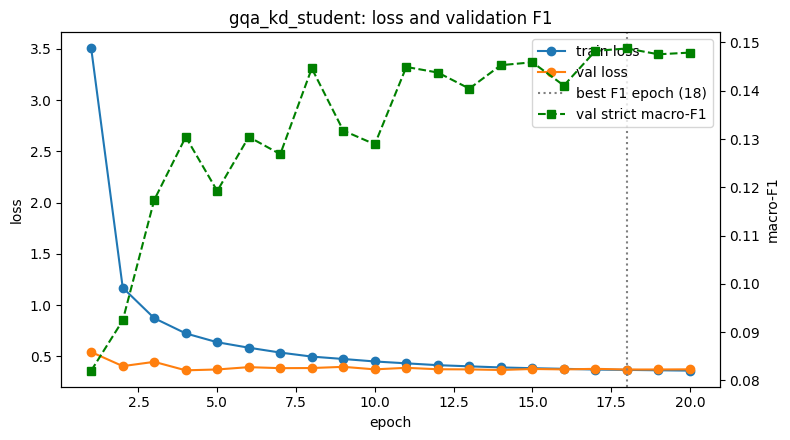

In [28]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train"]) + 1)
fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.plot(epochs, history["train"], marker="o", label="train loss")
ax1.plot(epochs, history["val"], marker="o", label="val loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")

ax2 = ax1.twinx()
ax2.plot(epochs, history["f1"], marker="s", color="green", linestyle="--", label="val strict macro-F1")
ax2.set_ylabel("macro-F1")

best = max(range(len(history["f1"])), key=lambda i: history["f1"][i]) + 1
ax1.axvline(best, color="gray", linestyle=":", label=f"best F1 epoch ({best})")

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.title(f"{EXPERIMENT_NAME}: loss and validation F1")
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=150)
plt.show()

## 14. Save Final Model to Kaggle Output

In [29]:
size_kb = os.path.getsize(MODEL_PATH) / 1024
print(f"saved student checkpoint: {size_kb:.0f} KB")

run_info = {
    "experiment": EXPERIMENT_NAME,
    "technique": "Knowledge Distillation",
    "phase1_model": "GQA (Model 3)",
    "teacher": "Prefix-LM (Model 4, full fine-tuned)",
    "kd_temperature": KD_TEMPERATURE, "kd_alpha": KD_ALPHA,
    "lr_backbone": LR_BACKBONE, "lr_head": LR_HEAD,
    "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE, "grad_accum": GRAD_ACCUM,
    "window": WINDOW_SIZE, "stride": WINDOW_STRIDE, "header_tokens": HEADER_TOKENS,
    "epochs_planned": EPOCHS, "epochs_run": len(history["f1"]),
    "best_epoch": history["f1"].index(max(history["f1"])) + 1,
    "best_val_f1": max(history["f1"]),
    "student_trainable_params": sum(p.numel() for p in ner_model.parameters() if p.requires_grad),
    "teacher_params": teacher_params,
    "checkpoint_kb": round(size_kb, 1),
    "train_seconds": round(time.time() - t0),
}
with open(os.path.join(OUTPUT_DIR, "run_info.json"), "w") as f:
    json.dump(run_info, f, indent=2)
print(run_info)

saved student checkpoint: 446017 KB
{'experiment': 'gqa_kd_student', 'technique': 'Knowledge Distillation', 'phase1_model': 'GQA (Model 3)', 'teacher': 'Prefix-LM (Model 4, full fine-tuned)', 'kd_temperature': 2.0, 'kd_alpha': 0.5, 'lr_backbone': 3e-05, 'lr_head': 0.001, 'weight_decay': 0.05, 'batch_size': 2, 'grad_accum': 8, 'window': 1024, 'stride': 512, 'header_tokens': 64, 'epochs_planned': 20, 'epochs_run': 20, 'best_epoch': 18, 'best_val_f1': 0.14876793915209202, 'student_trainable_params': 101578777, 'teacher_params': 101578777, 'checkpoint_kb': 446017.0, 'train_seconds': 2651}


## For reload purpose

In [30]:
# # rebuild exactly as in training, then load the saved student state dict
# teacher_lm = PrefixLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
#                        n_embd=TEACHER_N_EMBD, n_layer=TEACHER_N_LAYER, n_head=TEACHER_N_HEAD,
#                        n_kv_head=TEACHER_N_KV_HEAD)
# teacher_model = NERModel(teacher_lm, n_tags=len(TAGS), n_embd=TEACHER_N_EMBD)
# teacher_model.load_state_dict(torch.load(os.path.join(TEACHER_CKPT_DIR, "best_model.pt"), map_location=device))
# teacher_model.to(device).eval()
#
# student_lm = ScratchGroupedQueryLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
#                                     n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD, n_kv_head=N_KV_HEAD)
# ner_model = NERModel(student_lm, n_tags=len(TAGS), n_embd=N_EMBD)
# ner_model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
# ner_model.to(device).eval()

## Predict fold3

In [31]:
test_pred = {}
for d in test_text:                       # fold3 documents, all required IDs
    test_pred[d] = [[int(s), int(e), lab] for s, e, lab in predict_spans(ner_model, d)]

assert set(test_pred) == set(test_text), "missing or extra document ids"
print("docs:", len(test_pred), "| total spans:", sum(len(v) for v in test_pred.values()))

for d, spans in test_pred.items():
    n = len(test_text[d])
    for s, e, lab in spans:
        assert 0 <= s < e <= n and lab in LABELS, (d, s, e, lab)
print("format checks OK")
d0 = next(iter(test_pred))
print([(s, e, lab, test_text[d0][s:e]) for s, e, lab in test_pred[d0][:5]])

docs: 35 | total spans: 7623
format checks OK
[(18, 40, 'COURT', 'SUPREME COURT OF INDIA'), (41, 46, 'CASENO', 'CIVIL'), (70, 98, 'CASENO', 'CIVIL APPEAL NO.6580 OF 2008'), (99, 103, 'APP', 'ARIS'), (114, 162, 'CASENO', 'SPECIAL LEAVE PETITION (CIVIL) NO. 15449 OF 2004')]


## 21. Save prediction.json and Create CodaBench Submission ZIP

In [32]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(test_pred, f, ensure_ascii=False)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")     # must sit at the zip root

print("saved:", SUBMISSION_ZIP)
with zipfile.ZipFile(SUBMISSION_ZIP) as z:
    print(z.namelist())                                    # expect ['prediction.json']

saved: /kaggle/working/cs781_phase2/gqa_kd_student/submission.zip
['prediction.json']


In [34]:
import shutil
shutil.make_archive("/kaggle/working/phase2_backup", "zip", "/kaggle/working/cs781_phase2")
shutil.copy("/kaggle/working/a1_tokenizer.py", "/kaggle/working/cs781_phase2/a1_tokenizer.py")
print(os.path.getsize("/kaggle/working/phase2_backup.zip") / 1e6, "MB")

377.83875 MB
